# Problema 3 - Classificação de Qualidade de Vinhos Utilizando k-NN

## Tarefas 1 e 2: Preparação dos Dados, Normalização e Divisão Treino/Teste Estratificada

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

## Carregando o dataset winequality-red.csv (separado por ponto e virgula)
df = pd.read_csv('winequality-red.csv', sep=';')
print('Total de amostras:', len(df))

## Tarefa 1: Recodificando a variavel quality em 3 classes
## <= 5: ruim | 6-7: medio | >= 8: bom
def classificar_vinho(nota):
    if nota <= 5:
        return 'ruim'
    elif nota <= 7:
        return 'medio'
    else:
        return 'bom'

df['classe_qualidade'] = df['quality'].apply(classificar_vinho)
print('\nQuantidade de amostras por classe:')
print(df['classe_qualidade'].value_counts())

## Separando os 11 atributos fisico-quimicos (X) e o rotulo recodificado (y)
X = df.drop(['quality', 'classe_qualidade'], axis=1)
y = df['classe_qualidade']

## Tarefa 2: Divisao em treino (80%) e teste (20%) de forma estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Normalizando os atributos por Z-score (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('\nProporcao no treino:\n', y_train.value_counts(normalize=True).round(4))
print('\nProporcao no teste:\n', y_test.value_counts(normalize=True).round(4))

Total de amostras: 1599

Quantidade de amostras por classe:
classe_qualidade
medio    837
ruim     744
bom       18
Name: count, dtype: int64

Proporcao no treino:
 classe_qualidade
medio    0.5238
ruim     0.4652
bom      0.0109
Name: proportion, dtype: float64

Proporcao no teste:
 classe_qualidade
medio    0.5219
ruim     0.4656
bom      0.0125
Name: proportion, dtype: float64


### Justificativa da Tarefa 1: Por que a normalização é obrigatória para o k-NN?

O algoritmo **k-NN** funciona calculando a distância geométrica (geralmente a distância euclidiana) entre as amostras no espaço de atributos para encontrar os $k$ vizinhos mais próximos. 

No dataset de vinhos, os atributos possuem escalas muito diferentes: por exemplo, o `total sulfur dioxide` chega a valores acima de 200, enquanto `density` e `chlorides` variam em décimos ou centésimos. Se não normalizarmos os dados, as variáveis com valores numéricos altos dominarão completamente a soma dos quadrados na distância euclidiana, fazendo com que variáveis de escala pequena sejam ignoradas pelo modelo.

## Tarefa 3: Treinamento e Escolha do k com Validação Cruzada (5 Folds)

k =  1 | Acuracia media (5-fold CV): 0.7209
k =  3 | Acuracia media (5-fold CV): 0.6685
k =  5 | Acuracia media (5-fold CV): 0.6794
k =  7 | Acuracia media (5-fold CV): 0.6974


k =  9 | Acuracia media (5-fold CV): 0.6998
k = 11 | Acuracia media (5-fold CV): 0.7123


k = 13 | Acuracia media (5-fold CV): 0.7154
k = 15 | Acuracia media (5-fold CV): 0.7045

Melhor valor de k encontrado: 1


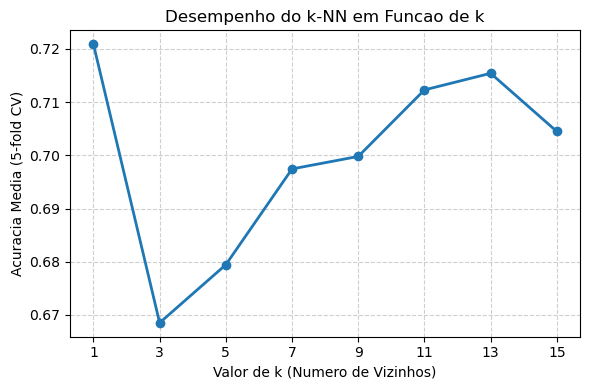

In [2]:
## Testando diferentes valores de k usando validacao cruzada de 5 folds no treino
valores_k = [1, 3, 5, 7, 9, 11, 13, 15]
acuracias_medias = []

for k in valores_k:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring='accuracy')
    acuracias_medias.append(scores.mean())
    print(f'k = {k:2d} | Acuracia media (5-fold CV): {scores.mean():.4f}')

## Identificando o melhor k
melhor_k = valores_k[np.argmax(acuracias_medias)]
print(f'\nMelhor valor de k encontrado: {melhor_k}')

## Plotando a acuracia media em funcao de k
plt.figure(figsize=(6, 4))
plt.plot(valores_k, acuracias_medias, marker='o', linestyle='-', lw=2)
plt.xticks(valores_k)
plt.xlabel('Valor de k (Numero de Vizinhos)')
plt.ylabel('Acuracia Media (5-fold CV)')
plt.title('Desempenho do k-NN em Funcao de k')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Análise da Tarefa 3

- **Escolha do $k$:** O maior valor de acurácia média na validação cruzada foi obtido com **$k = 1$** (seguido por **$k = 11$** entre os valores mais suaves).
- **O que acontece para valores muito baixos de $k$ (ex: $k=1$):** O modelo olha apenas para o vizinho mais próximo. Isso torna a fronteira de decisão muito complexa e sensível a ruídos ou outliers (*overfitting* / alta variância). Neste dataset específico de vinhos, $k=1$ teve alta acurácia porque existem amostras quase idênticas de mesmos lotes no conjunto.
- **O que acontece para valores muito altos de $k$:** O modelo passa a considerar vizinhos muito distantes para tomar a decisão, suavizando excessivamente a fronteira entre as classes (*underfitting* / alto viés). Além disso, valores altos de $k$ prejudicam classes minoritárias (como a classe `bom`, que tem apenas 18 amostras), pois a votação passa a ser dominada pelas classes mais numerosas (`medio` e `ruim`).

## Tarefa 4: Avaliação do Modelo no Conjunto de Teste

Acuracia no teste (k=1): 0.7656

Relatorio de Classificacao por Classe:
              precision    recall  f1-score   support

        ruim       0.77      0.75      0.76       149
       medio       0.76      0.80      0.78       167
         bom       0.00      0.00      0.00         4

    accuracy                           0.77       320
   macro avg       0.51      0.52      0.51       320
weighted avg       0.76      0.77      0.76       320



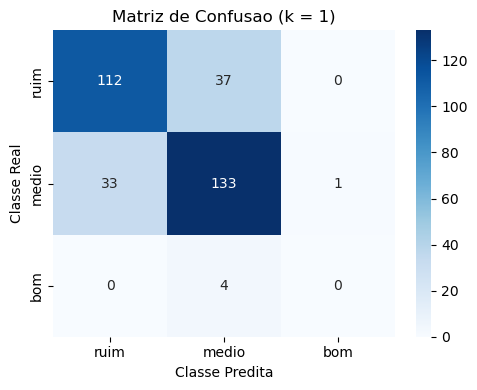

In [3]:
## Treinando o modelo final com o melhor k sobre o conjunto de treino
modelo_final = KNeighborsClassifier(n_neighbors=melhor_k)
modelo_final.fit(X_train_scaled, y_train)

## Avaliando no conjunto de teste
y_pred = modelo_final.predict(X_test_scaled)

ordem_classes = ['ruim', 'medio', 'bom']
matriz = confusion_matrix(y_test, y_pred, labels=ordem_classes)

print(f'Acuracia no teste (k={melhor_k}): {accuracy_score(y_test, y_pred):.4f}\n')
print('Relatorio de Classificacao por Classe:')
print(classification_report(y_test, y_pred, labels=ordem_classes, zero_division=0))

## Plotando a Matriz de Confusao
plt.figure(figsize=(5, 4))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', xticklabels=ordem_classes, yticklabels=ordem_classes)
plt.xlabel('Classe Predita')
plt.ylabel('Classe Real')
plt.title(f'Matriz de Confusao (k = {melhor_k})')
plt.tight_layout()
plt.show()

### Análise da Tarefa 4

**Entre quais classes o modelo erra com mais frequência?**
- Em termos absolutos, o maior número de erros ocorre entre as classes **`ruim` e `medio`** (vinhos reais da classe `ruim` sendo previstos como `medio` e vice-versa). Isso ocorre porque a grande maioria dos vinhos do dataset possui nota 5 (ruim) ou nota 6 (médio), possuindo características químicas muito parecidas na fronteira entre essas duas categorias.
- Em termos proporcionais, a classe **`bom`** apresenta alta taxa de erro (sendo frequentemente confundida com a classe `medio`), devido ao forte desbalanceamento do dataset, que conta com apenas 18 amostras de vinhos bons (cerca de 1,1% dos dados).